# 1. Thresholding

### 1.1 	T=55; 2) T=129; 3) T=200;

a)	Visualize 6 output images.

b)	Write your observations about thresholded images at different thresholds. How many and which digits are segmented at each threshold? What else do you observe at each threshold?



In [ ]:
#modules
import numpy as np
import matplotlib.pyplot as plt
import cv2




def threshFunction():
  #Given
  T = [55,129,200]

  #input
  image = cv2.imread("digits.png")
  thresholding = [
      cv2.THRESH_BINARY,
      cv2.THRESH_BINARY_INV,
  ]
  thresholdingName = ["Bin","InvBin"]
  grayImg = cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)

  plt.figure(figsize=(6,10))


  #Output
  for i in range(len(T)):
    for j in range(len(thresholding)):
      index = i*len(thresholding)+j+1
      plt.subplot(3,2,index)
      _,imgThres = cv2.threshold(grayImg, T[i],255,thresholding[j])
      plt.imshow(imgThres, cmap = 'gray')
      plt.title(f"Thresh={T[i]}|{thresholdingName[j]}")

  plt.show()

if __name__ == '__main__':
  threshFunction()




## Observation

When T = 55,
  
1.   for Binary, we can see that number "1" is visible with 0(black) pixel value while the rest of the other region is 255(white) pixel value
2.   for Inverse binary, we can see that number only number "1" is visihle with 255(white) pixel value while rest of the other region is 0(black) pixel value

When T = 129,
  
1.   for Binary, we can see that number "2" and "5" is visible with 255(white) pixel value while the rest of the other region is 0(black) pixel value
2.   for Inverse binary, we can see that number "2" and "5" is visible with 0(black) pixel value while the rest of the other region is 255(white) pixel value

When T = 200,
  
1.   for Binary, we can see that number "2" is visible with 255(white) pixel value while the rest of the other region is 0(black) pixel value
2.   for Inverse binary, we can see that number "2" is visible with 0(black) pixel value while the rest of the other region is 255(white) pixel value

## Conclusion

We observe that while changing the threshold value the visiblity of digits is also affected. Binary and Inverse binary thresholding gives complete oposite output by inversing the pixel value.
  

### 1.2 	Threshold the image using Window binary thresholding (i.e., 255 if T_1  <I_(i,j)  <T_2 and 0 otherwise) using three different range of thresholds.
1) T_1=55 and T_2=90; 2) T_1=90 and T_2=129; 3) T_1=129 and T_2=200;



a)	Visualize 3 output images.

b)	Write your observations. How many and which digits are segmented at each threshold? What else do you observe at each threshold




In [ ]:
#modules
import numpy as np
import matplotlib.pyplot as plt
import cv2




def threshFunction():
  #Given
  windows=[(55,90),(90,129),(129,200)]

  #input
  image = cv2.imread("digits.png")
  binary = cv2.THRESH_BINARY

  grayImg = cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)

  plt.figure(figsize=(6,10))


  #Output
  for i,(low,high) in enumerate(windows):
    result = np.where((grayImg>=low) & (grayImg<=high),
                      255,0
                      ).astype(np.uint8)

    plt.subplot(1,3,i+1)
    plt.imshow(result,cmap='gray')
    plt.title(f"Windows:{low}-{high}")
  plt.show()
  print(grayImg)

if __name__ == '__main__':
  threshFunction()




##Observation


1.   Window(55-90), Only pixels with intensity values between 55 and 90 becomes 255(white) as rest of the pixel's intensity becomes 0(black), Hence "4" digit is appeared as it lies in range(55-90)
2.   Window(90-129), Only pixels with intensity values between 90 and 129 becomes 255(white) as rest of the pixel becomes 0(black), Hence "1","2",""4","5" digits are appeared as rest of the pixels becomes 255(white) as they lies in (90-129).  Here the circle at center and digit "3" becomes black as their pixel value doesnt come in range(90-129) yet it is not visible in original image as their intensity value is near to background intensity
3. Window(129-200), Only pixels with intensity values between 129 and 200 becomes 255(white) as rest of the pixel becomes 0(black), Hence the slightly visible"3", the circle and "5" digit are appeared as it's intensity lies in range(129,200)

##Conclusion

Window binary thresholding selects pixels within a specified range. Here if the background and digits intensity both either falls in the same range or both does not, the digit wont be visible. Therefore effectiveness of window thresholding depends intensity distribution of the image

###1.3	In a practical application, we vary the value of the hyper-parameters (here,the threshold values) for any of the above-mentioned thresholding methods, such that we get the desired output.
a)	Find threshold values that segment only the digit ‘3’ (all other digits must remain background) and visualize the output images (i.e., considered as foreground – white pixel – 255 value).

b)	Can you find a threshold value or values of the above-mentioned thresholding methods such that only digit 3 is segmented (nothing else, foreground pixels).  If you can find, show threshold values. If you cannot find, explain the reason.


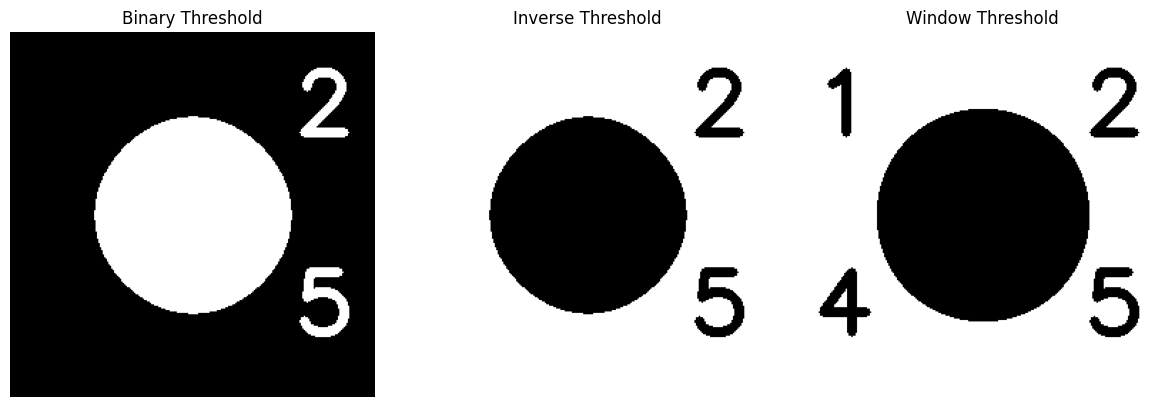

In [13]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image = cv2.imread("digits.png")

# Binary thresholding
_, binary = cv2.threshold(image, 129, 255, cv2.THRESH_BINARY)

# Inverse binary thresholding
_, inverse = cv2.threshold(image, 129, 255, cv2.THRESH_BINARY_INV)

# Window thresholding
window = np.where((image > 90) & (image < 129), 255, 0).astype(np.uint8)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(binary, cmap='gray')
plt.title('Binary Threshold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(inverse, cmap='gray')
plt.title('Inverse Threshold')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(window, cmap='gray')
plt.title('Window Threshold')
plt.axis('off')

plt.tight_layout()
plt.show()


##Observations:

1. Binary thresholding: Several different threshold values were tested to digit ‘3’ from the background.. The problem was that other digits also showed up as foreground because their pixel intensities were similar to those of digit ‘3’.

2. Inverse binary thresholding: This method flipped the intensity levels making the background white and the digits black. The visibility of the digits changed,. Still digit ‘3’ could not be reliably separated from the others.

3. Window thresholding: Different intensity ranges were used to keep pixels within a certain range. This made some parts of the digits visible. Again other digits appeared too because they had pixel values in that same range.

4. It was not possible to isolate digit ‘3’ perfectly using the global threshold methods tested. These methods only look at pixel intensity. Don’t consider the shape or the actual identity of the digit. Since different digits can have overlapping intensity levels a single threshold or intensity window cannot separate digit ‘3’, from all other digits. To do this properly a better approach is needed—like using information or training a digit recognition model. That way the system can recognize digit ‘3’ based on its shape, not its brightness.